# 03 - Erro com pontos flutuantes
Vamos aprender sobre como usar os erros de ponto flutuante para resolução de problemas numéricos.

Crie uma nova branch (versão) do repositório:

```bash
git branch semana3
```

Faça o checkout nessa nova branch:

```bash
git checkout semana3
```

<hr />

## Atividade 1
A função exponencial natural pode ser definida pelo limite:
$$
e^x=\lim_{n\to\infty}\left(1+\frac{x}{n}\right)^n,
$$
mas também é dada pela **série de Maclaurin**:
$$
e^x=\sum_{n=0}^{\infty}\frac{x^n}{n!}
=1+\frac{x}{1!}+\frac{x^2}{2!}+\frac{x^3}{3!}+\cdots
$$

Implemente em **Python** o cálculo de $e^x$ pela série, interrompendo a soma quando o termo ficar menor que o limite prático de contribuição, usando a precisão de máquina como critério.

In [2]:
import math
import sys

def exp_series(x, atol=0.0):
    """ Aproxima e^x pela série de Maclaurin com critério de parada numérico. """
    eps = sys.float_info.epsilon
    s = 1.0
    term = 1.0
    n = 0
    tol_abs = max(atol, eps)

    while True:
        n += 1
        term *= x / n
        s += term
        if abs(term) < eps * abs(s) or abs(term) < tol_abs:
            break
        if n > 10_000:
            break
    return s, n, term

# Demonstração
for val in [1.0, 5.0, -2.0]:
    approx, nterms, last = exp_series(val)
    print(f"x={val:+g} -> e^x ≈ {approx:.16g} (math.exp={math.exp(val):.16g}, termos={nterms})")

x=+1 -> e^x ≈ 2.718281828459046 (math.exp=2.718281828459045, termos=18)
x=+5 -> e^x ≈ 148.4131591025766 (math.exp=148.4131591025766, termos=33)
x=-2 -> e^x ≈ 0.1353352832366127 (math.exp=0.1353352832366127, termos=24)


## Atividade 2

Implemente:
$$
e^x\approx\left(1+\frac{x}{n}\right)^n
$$
com $n$ crescente, e:
1. Explique por que, para $x<0$ e $n$ muito grande, pode ocorrer **cancelamento catastrófico**;
2. Proponha um critério de parada numérico para encerrar o crescimento de $n$ sem perder precisão.

#### RESPOSTA

1. Quando $x$ é um número negativo (ex: $x = -2$), a expressão $(1 + \frac{x}{n})$ transforma-se em uma subtração: $(1 - \frac{\vert{}x\vert{}}{n})$. À medida que $n$ se torna muito grande, o termo $\frac{\vert{}x\vert{}}{n}$ torna-se um número muito próximo de zero. Eventualmente, para um $n$ gigantesco, a equação $1 - \frac{\vert{}x\vert{}}{n}$ tende para 1. Elevando 1 a potência $n$, o resultado é 1.

In [1]:
import math

def exp_limit(x):
    """ 
    Aproxima e^x pelo limite (1 + x/n)^n com n crescente 
    e um critério de parada focado no limite numérico prático.
    """
    n = 1
    val_prev = (1 + x / n) ** n
    diff_prev = float('inf')
    
    while True:
        n *= 2  # Crescimento geométrico de n para acelerar a busca
        
        # Avalia a função com o novo n
        val_curr = (1 + x / n) ** n
        
        # Calcula a diferença entre a aproximação atual e a anterior
        diff_curr = abs(val_curr - val_prev)
        
        if diff_curr >= diff_prev or diff_curr == 0.0:
            # Retorna o valor anterior (o mais preciso antes da piora) e o respectivo n
            return val_prev, n // 2
            
        # Atualiza as variáveis para a próxima iteração
        val_prev = val_curr
        diff_prev = diff_curr

print("Comparação: Limite (Atividade 2) vs math.exp (Real)")
for val in [1.0, 5.0, -2.0]:
    approx, best_n = exp_limit(val)
    real_val = math.exp(val)
    print(f"x={val:+g} -> e^x ≈ {approx:.10g} (Real={real_val:.10g}, melhor n={best_n})")

Comparação: Limite (Atividade 2) vs math.exp (Real)
x=+1 -> e^x ≈ 2.718281828 (Real=2.718281828, melhor n=2251799813685248)
x=+5 -> e^x ≈ 12.25 (Real=148.4131591, melhor n=2)
x=-2 -> e^x ≈ 0.1353352832 (Real=0.1353352832, melhor n=4503599627370496)


## Atividade 3

Para $|x|$ grande, use:
$$
e^x = \left(e^{m\cdot 2^{-k}}\right)^{2^k}, \quad
k = \left\lceil \log_2\!\left(\frac{|x|}{\theta}\right)\right\rceil, \quad m = \frac{x}{2^k}
$$
Calcule $e^{m}$ pela série (Ex. 1) e depois eleve ao quadrado $k$ vezes.

In [ ]:
import math
import sys

# 1. (Série de Maclaurin)
def exp_series(x, atol=0.0):
    eps = sys.float_info.epsilon
    s = 1.0
    term = 1.0
    n = 0
    tol_abs = max(atol, eps)

    while True:
        n += 1
        term *= x / n
        s += term
        
        # Critério de parada da máquina
        if abs(term) < eps * abs(s) or abs(term) < tol_abs:
            break
        if n > 10_000:
            break
    return s

# 2. Nova Função: Redução de argumento e quadratura (scaling and squaring)
def exp_large_x(x, theta=1.0):
    # Calcula o número de divisões necessárias (k)
    if abs(x) <= theta:
        k = 0
    else:
        # k = teto( log2(|x| / theta) )
        k = math.ceil(math.log2(abs(x) / theta))
    
    m = x / (2 ** k)
    
    resultado = exp_series(m)
    
    for _ in range(k):
        resultado *= resultado
        
    return resultado, k, m

if __name__ == "__main__":
    print(f"{'x':>5} | {'k (quadraturas)':>15} | {'m (reduzido)':>12} | {'Resultado Calculado':>20} | {'math.exp(x) (Real)':>20}")
    print("-" * 85)
    
    # Testando com valores grandes positivos e negativos
    for val in [2.5, 10.0, -20.0, 50.0]:
        calc, k_val, m_val = exp_large_x(val)
        real = math.exp(val)
        
        print(f"{val:>5.1f} | {k_val:>15} | {m_val:>12.5f} | {calc:>20.10e} | {real:>20.10e}")

    x | k (quadraturas) | m (reduzido) |  Resultado Calculado |   math.exp(x) (Real)
-------------------------------------------------------------------------------------
  2.5 |               2 |      0.62500 |     1.2182493961e+01 |     1.2182493961e+01
 10.0 |               4 |      0.62500 |     2.2026465795e+04 |     2.2026465795e+04
-20.0 |               5 |     -0.62500 |     2.0611536224e-09 |     2.0611536224e-09
 50.0 |               6 |      0.78125 |     5.1847055286e+21 |     5.1847055286e+21


## Atividade 4

Use:
$$
\cos x=\sum_{n=0}^{\infty}(-1)^n\frac{x^{2n}}{(2n)!}
$$
com a recursão:
$$
t_{n+1}=t_n\cdot\frac{-x^2}{(2n+1)(2n+2)}
$$
Defina um critério de parada baseado em `epsilon` e compare o erro relativo para $x\in[-20,20]$ (200 pontos) contra `math.cos(x)`.

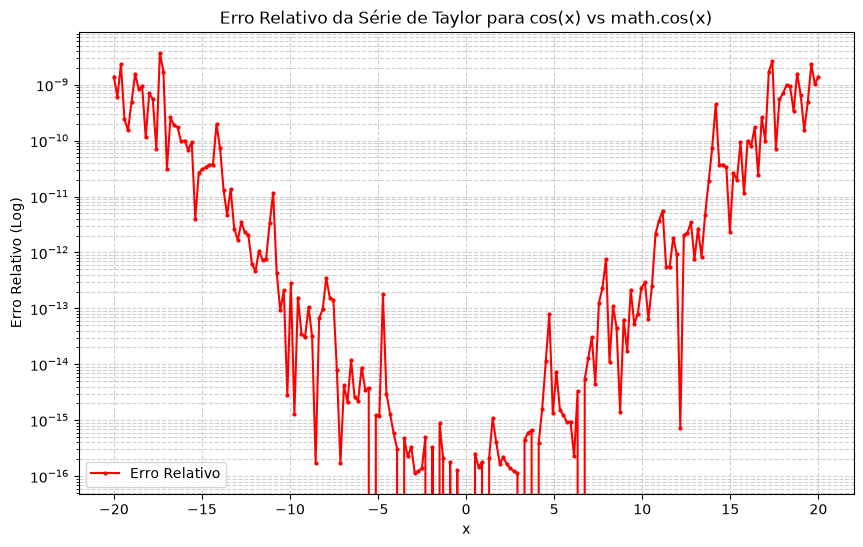

In [6]:
import math
import sys
import numpy as np
import matplotlib.pyplot as plt

def cos_series(x):
    eps = sys.float_info.epsilon
    s = 1.0     # O primeiro termo (n=0) é 1
    term = 1.0  # t_0 = 1
    n = 0
    
    while True:

        term *= (-x**2) / ((2 * n + 1) * (2 * n + 2))
        s += term
        n += 1
        
        # Critério de parada baseado no Epsilon da máquina
        if abs(term) < eps * abs(s) or abs(term) < eps:
            break
            
        # Trava de segurança para evitar loops infinitos
        if n > 1000:
            break
            
    return s

# ---------------------------------------------------------
# Análise de Erro Relativo

x_vals = np.linspace(-20, 20, 200)
erros_relativos = []

for x in x_vals:
    approx = cos_series(x)
    exato = math.cos(x)
    
    # Evita divisão por zero caso o math.cos(x) seja exatamente zero
    # Adicionando um pequeno delta no denominador
    divisor = abs(exato) if abs(exato) > 1e-12 else 1e-12
    
    # Cálculo do erro relativo: |(Aproximado - Exato) / Exato|
    erro_rel = abs(approx - exato) / divisor
    erros_relativos.append(erro_rel)

# ---------------------------------------------------------
# Visualização Gráfica
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))
plt.plot(x_vals, erros_relativos, label="Erro Relativo", color="red", marker='.', markersize=4, linestyle='-')
plt.yscale("log") # Escala logarítmica evidencia ordens de grandeza do erro
plt.title("Erro Relativo da Série de Taylor para cos(x) vs math.cos(x)")
plt.xlabel("x")
plt.ylabel("Erro Relativo (Log)")
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend()
plt.show()

## Atividade 5

Dado $x$ e uma tolerância $\tau$, encontre o menor $N$ tal que:
$$
R_{N+1}(x)=\sum_{n=N+1}^{\infty}\frac{|x|^n}{n!} < \tau
$$

In [7]:
import math

def encontrar_menor_N(x, tau):
    """
    Dado x e uma tolerância tau, encontra o menor inteiro N 
    tal que o resto da série seja menor que tau.
    """
    abs_x = abs(x)
    valor_exato = math.exp(abs_x) 
    
    soma_parcial = 0.0
    termo = 1.0  
    N = 0
    
    while True:
        
        soma_parcial += termo
        
        resto = valor_exato - soma_parcial
        
        if resto < tau or resto <= 0.0:
            return N
            
        N += 1
        
        termo *= abs_x / N

# Teste de Validação

if __name__ == "__main__":
    x_teste = 2.5
    tau_teste = 1e-6
    
    N_encontrado = encontrar_menor_N(x_teste, tau_teste)
    
    print(f"Parâmetros: x = {x_teste}, tau = {tau_teste}")
    print(f"O menor N necessário é: {N_encontrado}")

Parâmetros: x = 2.5, tau = 1e-06
O menor N necessário é: 14


## Atividade 6

Usando `decimal` ou `mpmath`, compute $e^x$ em alta precisão e compare com o resultado de `float64` (Ex. 1) para $x\in\{20, 40, 50\}$.
Analise:
- perda de dígitos significativos;
- quando o `float64` começa a saturar por overflow.


In [8]:
import sys
import decimal

# Configura a precisão do módulo decimal para 50 casas
decimal.getcontext().prec = 50

def exp_series_float64(x):
    """Calcula e^x usando a Série de Maclaurin (recursiva) em float64."""
    eps = sys.float_info.epsilon
    s = 1.0
    term = 1.0
    n = 0
    
    while True:
        n += 1
        term *= (x / n)
        s += term
        
        # Parada quando o termo for irrelevante perante a soma
        if abs(term) < eps * abs(s):
            break
            
    return s, n

# Valores a serem avaliados
valores = [20.0, 40.0, 50.0]

print(f"{'x':>4} | {'float64 (Ex. 1)':>25} | {'decimal (Alta Precisão)':>28} | {'Erro Absoluto':>15} | {'Termos (n)'}")
print("-" * 95)

for x in valores:
    # Cálculo em float64
    calc_float, n_termos = exp_series_float64(x)
    
    # Cálculo em alta precisão (decimal)
    x_dec = decimal.Decimal(x)
    calc_dec = x_dec.exp()
    
    # Diferença para evidenciar a perda de precisão
    # Convertendo o float64 para Decimal para realizar a subtração com precisão
    erro_abs = abs(calc_dec - decimal.Decimal(calc_float))
    
    print(f"{x:>4.0f} | {calc_float:>25.5f} | {calc_dec:>28.5f} | {erro_abs:>15.2e} | {n_termos}")

   x |           float64 (Ex. 1) |      decimal (Alta Precisão) |   Erro Absoluto | Termos (n)
-----------------------------------------------------------------------------------------------
  20 |           485165195.40979 |              485165195.40979 |         1.78e-7 | 67
  40 |  235385266837020064.00000 |     235385266837019985.40790 |         7.86e+1 | 102
  50 | 5184705528587081482240.00000 | 5184705528587072464087.45332 |         9.02e+6 | 118


1. O tipo float64 possui uma precisão máxima de 15 a 17 dígitos decimais significativos, por isso,  os últimos 5 dígitos inteiros de $e^{50}$ são completamente perdidos, fazendo com que o erro absoluto cresça exponencialmente, chegando a uma grande diferença em relação ao valor real puramente por falta de espaço de armazenamento.

2. O valor máximo absoluto que um float64 pode armazenar é aproximadamente $1.79 \times 10^{308}$. O overflow do resultado final $e^x$ só ocorrerá quando a exponenciação ultrapassar esse limite. Isso acontece em: $$x \approx 709.78$$ Portanto, para $x \ge 710$, a linguagem lançará um erro. Os valores exigidos (20, 40, 50) não estouram a variável de soma.

## Versionando o código

Submeta a branch para o servidor:

```bash
git add .
git commit -m "Semana 3"
git push origin semana3
```